# 05 Context-Aware Model


## 1. Load Dataset and Fixed Split


In [8]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path(
    r"D:\JupyterProject\AIML339_Toxicity"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "labeled_context_1200.parquet"
)

SPLIT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "dataset_split.parquet"
)

df = pd.read_parquet(DATA_PATH)
split_data = pd.read_parquet(SPLIT_PATH)

print("Dataset:")
print(df.shape)

print("\nSplit data:")
print(split_data.shape)

Dataset:
(1200, 26)

Split data:
(1200, 3)


## 2. Add Fixed Data Split


In [9]:
df = df.merge(
    split_data[
        [
            "annotation_id",
            "split"
        ]
    ],
    on="annotation_id",
    how="left",
    validate="one_to_one"
)

print(
    df["split"]
    .value_counts()
)

print(
    "\nMissing split:",
    df["split"].isna().sum()
)

split
train         838
validation    183
test          179
Name: count, dtype: int64

Missing split: 0


## 3. Build Chat History Text


In [10]:
history_columns = [
    "prev_message_5",
    "prev_message_4",
    "prev_message_3",
    "prev_message_2",
    "prev_message_1"
]

df["history_text"] = (
    df[history_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

df["current_text"] = (
    df["key"]
    .fillna("")
    .astype(str)
)

display(
    df[
        [
            "current_text",
            "history_text",
            "label"
        ]
    ].head(10)
)

,current_text,history_text,label
0,man ur life must be shit,retard if u didnt suck so much we coudla playe...,2
1,dont know why,steo by step we will relax fuck valve fuck me,0
2,can u end,im sure he proved to be a real challenge mid k...,0
3,noob jugger,how did you get those mmr storm account buyer ...,2
4,it is not about how bad he is,win lol hehe dp won i tried to win he tried to...,1
5,bara,bara retarded gg report pls blood ez im going ...,0
6,yes storm was bad,be positive fk urslrf are you ready? fking sto...,1
7,noob am,i dont know whats top and mid mid no impact gg...,2
8,wtf is that,GIVE UP 1 bloodstone no aghs lina vs huskar do...,1
9,sorry jugg,Gg lol gg ez gg,0


## 4. Select Context Features


In [11]:
numeric_features = [
    "messages_last_60s",
    "message_interval",
    "gold",
    "xp",
    "last_hits",
    "seconds_since_teamfight"
]

binary_features = [
    "repeated_message_60s",
    "recent_teamfight_120s",
    "recent_teamfight_loss_120s"
]

context_features = (
    numeric_features
    + binary_features
)

print("Numeric features:")
print(numeric_features)

print("\nBinary features:")
print(binary_features)

print("\nMissing values:")
print(
    df[context_features]
    .isna()
    .sum()
)

Numeric features:
['messages_last_60s', 'message_interval', 'gold', 'xp', 'last_hits', 'seconds_since_teamfight']

Binary features:
['repeated_message_60s', 'recent_teamfight_120s', 'recent_teamfight_loss_120s']

Missing values:
messages_last_60s               0
message_interval              251
gold                            0
xp                              0
last_hits                       0
seconds_since_teamfight       135
repeated_message_60s            0
recent_teamfight_120s           0
recent_teamfight_loss_120s      0
dtype: int64


## 5. Create Train and Validation Data


In [12]:
train_df = df[
    df["split"] == "train"
].copy()

val_df = df[
    df["split"] == "validation"
].copy()

test_df = df[
    df["split"] == "test"
].copy()

print("Train:")
print(len(train_df))

print("\nValidation:")
print(len(val_df))

print("\nTest:")
print(len(test_df))

Train:
838

Validation:
183

Test:
179


## 6. Process Current Message Text


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

current_tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_features=5000,
    sublinear_tf=True
)

X_train_current_tfidf = (
    current_tfidf.fit_transform(
        train_df["current_text"]
    )
)

X_val_current_tfidf = (
    current_tfidf.transform(
        val_df["current_text"]
    )
)

print("Current text TF-IDF:")
print(X_train_current_tfidf.shape)

Current text TF-IDF:
(838, 397)


In [14]:
current_svd = TruncatedSVD(
    n_components=50,
    random_state=339
)

X_train_current = (
    current_svd.fit_transform(
        X_train_current_tfidf
    )
)

X_val_current = (
    current_svd.transform(
        X_val_current_tfidf
    )
)

print("Current text after SVD:")
print(X_train_current.shape)

print("\nExplained variance:")
print(
    current_svd
    .explained_variance_ratio_
    .sum()
)

Current text after SVD:
(838, 50)

Explained variance:
0.5716270057408508


## 7. Process Chat History


In [15]:
history_tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_features=5000,
    sublinear_tf=True
)

X_train_history_tfidf = (
    history_tfidf.fit_transform(
        train_df["history_text"]
    )
)

X_val_history_tfidf = (
    history_tfidf.transform(
        val_df["history_text"]
    )
)

print("History TF-IDF:")
print(X_train_history_tfidf.shape)

History TF-IDF:
(838, 1255)


In [16]:
history_svd = TruncatedSVD(
    n_components=50,
    random_state=339
)

X_train_history = (
    history_svd.fit_transform(
        X_train_history_tfidf
    )
)

X_val_history = (
    history_svd.transform(
        X_val_history_tfidf
    )
)

print("History after SVD:")
print(X_train_history.shape)

print("\nExplained variance:")
print(
    history_svd
    .explained_variance_ratio_
    .sum()
)

History after SVD:
(838, 50)

Explained variance:
0.2934685573067951


## 8. Process Numeric Context Features


In [17]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)

X_train_numeric = (
    numeric_imputer.fit_transform(
        train_df[numeric_features]
    )
)

X_val_numeric = (
    numeric_imputer.transform(
        val_df[numeric_features]
    )
)

numeric_scaler = StandardScaler()

X_train_numeric = (
    numeric_scaler.fit_transform(
        X_train_numeric
    )
)

X_val_numeric = (
    numeric_scaler.transform(
        X_val_numeric
    )
)

print("Numeric context shape:")
print(X_train_numeric.shape)

Numeric context shape:
(838, 8)


## 9. Prepare Binary Context Features


In [18]:
X_train_binary = (
    train_df[binary_features]
    .astype(float)
    .to_numpy()
)

X_val_binary = (
    val_df[binary_features]
    .astype(float)
    .to_numpy()
)

print("Binary context shape:")
print(X_train_binary.shape)

Binary context shape:
(838, 3)


## 10. Combine All Features


In [19]:
X_train_context = np.hstack([
    X_train_current,
    X_train_history,
    X_train_numeric,
    X_train_binary
])

X_val_context = np.hstack([
    X_val_current,
    X_val_history,
    X_val_numeric,
    X_val_binary
])

print("Training input shape:")
print(X_train_context.shape)

print("\nValidation input shape:")
print(X_val_context.shape)

Training input shape:
(838, 111)

Validation input shape:
(183, 111)


## 11. Prepare Labels


In [21]:
y_train_context = (
    train_df["label"]
    .astype(int)
    .to_numpy()
)

y_val_context = (
    val_df["label"]
    .astype(int)
    .to_numpy()
)

print("Training labels:")
print(y_train_context.shape)

print("\nValidation labels:")
print(y_val_context.shape)

print("\nTraining label distribution:")
print(
    pd.Series(y_train_context)
    .value_counts()
    .sort_index()
)

Training labels:
(838,)

Validation labels:
(183,)

Training label distribution:
0    281
1    313
2    244
Name: count, dtype: int64


## 12. Convert Data to PyTorch Tensors


In [23]:
import torch
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(339)

X_train_tensor = torch.tensor(
    X_train_context,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_context,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_context,
    dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_val_context,
    dtype=torch.long
)

print("Training tensor:")
print(X_train_tensor.shape)

print("\nValidation tensor:")
print(X_val_tensor.shape)

Training tensor:
torch.Size([838, 111])

Validation tensor:
torch.Size([183, 111])


In [24]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

print("Training batches:")
print(len(train_loader))

Training batches:
27


## 13. Define Context-Aware MLP


In [25]:
import torch.nn as nn

input_size = X_train_tensor.shape[1]

class ContextMLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, 3)
        )

    def forward(self, x):
        return self.network(x)


model = ContextMLP(
    input_size
)

print(model)

print("\nInput size:")
print(input_size)

ContextMLP(
  (network): Sequential(
    (0): Linear(in_features=111, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=3, bias=True)
  )
)

Input size:
111


## 14. Prepare Training Settings


In [27]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Device:")
print(device)

Device:
cpu


## 15. Train Context-Aware MLP


In [28]:
from sklearn.metrics import f1_score
import copy

num_epochs = 50
best_val_f1 = 0
best_epoch = 0
best_model_state = None

training_history = []

for epoch in range(num_epochs):

    model.train()

    total_loss = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(
            outputs,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    model.eval()

    with torch.no_grad():

        val_outputs = model(
            X_val_tensor.to(device)
        )

        val_predictions = (
            torch.argmax(
                val_outputs,
                dim=1
            )
            .cpu()
            .numpy()
        )

    val_f1 = f1_score(
        y_val_context,
        val_predictions,
        average="macro"
    )

    average_loss = (
        total_loss
        / len(train_loader)
    )

    training_history.append(
        {
            "epoch": epoch + 1,
            "loss": average_loss,
            "val_macro_f1": val_f1
        }
    )

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

    if (
        epoch == 0
        or (epoch + 1) % 5 == 0
    ):

        print(
            f"Epoch {epoch + 1:02d} | "
            f"Loss: {average_loss:.4f} | "
            f"Val Macro-F1: {val_f1:.4f}"
        )

Epoch 01 | Loss: 1.0947 | Val Macro-F1: 0.2892
Epoch 05 | Loss: 1.0229 | Val Macro-F1: 0.5499
Epoch 10 | Loss: 0.5742 | Val Macro-F1: 0.7659
Epoch 15 | Loss: 0.4091 | Val Macro-F1: 0.8062
Epoch 20 | Loss: 0.3439 | Val Macro-F1: 0.8034
Epoch 25 | Loss: 0.2808 | Val Macro-F1: 0.8076
Epoch 30 | Loss: 0.2460 | Val Macro-F1: 0.8043
Epoch 35 | Loss: 0.2238 | Val Macro-F1: 0.8249
Epoch 40 | Loss: 0.2246 | Val Macro-F1: 0.8101
Epoch 45 | Loss: 0.1793 | Val Macro-F1: 0.8070
Epoch 50 | Loss: 0.1385 | Val Macro-F1: 0.7969


In [29]:
print("Best epoch:")
print(best_epoch)

print("\nBest validation Macro-F1:")
print(best_val_f1)

Best epoch:
35

Best validation Macro-F1:
0.8248747638991542


## 16. Restore Best Model


In [30]:
model.load_state_dict(
    best_model_state
)

model.eval()

print(
    "Best model restored."
)

Best model restored.


## 17. Evaluate Best Context Model


In [31]:
from sklearn.metrics import (
    classification_report,
    f1_score
)

model.eval()

with torch.no_grad():

    val_outputs = model(
        X_val_tensor.to(device)
    )

    context_val_predictions = (
        torch.argmax(
            val_outputs,
            dim=1
        )
        .cpu()
        .numpy()
    )

context_macro_f1 = f1_score(
    y_val_context,
    context_val_predictions,
    average="macro"
)

print("Context Model Macro F1:")
print(context_macro_f1)

print("\nClassification Report:")

print(
    classification_report(
        y_val_context,
        context_val_predictions,
        target_names=[
            "Normal",
            "Limited Emotional",
            "Harmful"
        ],
        digits=3
    )
)

Context Model Macro F1:
0.8248747638991542

Classification Report:
                   precision    recall  f1-score   support

           Normal      0.781     0.847     0.813        59
Limited Emotional      0.882     0.789     0.833        76
          Harmful      0.804     0.854     0.828        48

         accuracy                          0.825       183
        macro avg      0.823     0.830     0.825       183
     weighted avg      0.829     0.825     0.825       183



## 18. Compare Context Model with Baseline


In [32]:
comparison = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "Context-Aware MLP"
    ],
    "Macro F1": [
        0.8213,
        context_macro_f1
    ]
})

display(comparison)

,Model,Macro F1
0,TF-IDF + Logistic Regression,0.821300
1,Context-Aware MLP,0.824875


## 19. Context Model Confusion Matrix


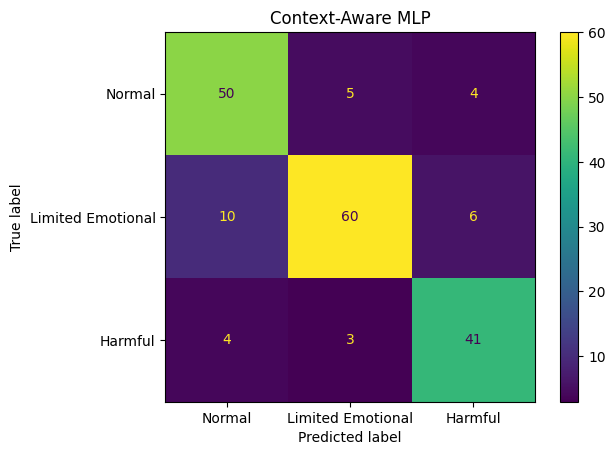

In [33]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

cm_context = confusion_matrix(
    y_val_context,
    context_val_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_context,
    display_labels=[
        "Normal",
        "Limited Emotional",
        "Harmful"
    ]
)

disp.plot()

plt.title(
    "Context-Aware MLP"
)

plt.show()

## 20. Save Best Context Model


In [34]:
import joblib

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

torch.save(
    model.state_dict(),
    MODEL_DIR / "context_mlp.pt"
)

joblib.dump(
    current_tfidf,
    MODEL_DIR / "context_current_tfidf.joblib"
)

joblib.dump(
    current_svd,
    MODEL_DIR / "context_current_svd.joblib"
)

joblib.dump(
    history_tfidf,
    MODEL_DIR / "context_history_tfidf.joblib"
)

joblib.dump(
    history_svd,
    MODEL_DIR / "context_history_svd.joblib"
)

joblib.dump(
    numeric_imputer,
    MODEL_DIR / "context_numeric_imputer.joblib"
)

joblib.dump(
    numeric_scaler,
    MODEL_DIR / "context_numeric_scaler.joblib"
)

print("Context model components saved.")

Context model components saved.


## 21. Save Context Validation Predictions


In [35]:
context_validation_results = val_df[
    [
        "annotation_id",
        "match_id",
        "key",
        "label"
    ]
].copy()

context_validation_results[
    "context_prediction"
] = context_val_predictions

CONTEXT_VALIDATION_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "context_validation_predictions.parquet"
)

context_validation_results.to_parquet(
    CONTEXT_VALIDATION_PATH,
    index=False
)

print("Saved to:")
print(CONTEXT_VALIDATION_PATH)

print("\nRows:")
print(len(context_validation_results))

Saved to:
D:\JupyterProject\AIML339_Toxicity\data\processed\context_validation_predictions.parquet

Rows:
183
